# chip_09_sim — the earlier frequency plan of chip_09 (legacy QWri `_sim` variant), on the Quantcore PDK

## 1 · What the chip is

**Source:** `components/python/chip_09_resonatorsExpt_sim.py` (`create_test_chip`, output
`chip_09_test_res_<size>_sim.oas`), Quantcore internal. Spec: `docs/designs/legacy/chip_09_resonators_expt.md`
(section "The `_sim` variant"); the measured-chip version is the notebook `chip_09_resonators_expt`.

chip_09's serpentine 15.7 mm 10/6 µm feedline between the same two bond pads, with six `Coupled Resonator`s on
an **earlier frequency plan**: R2 7.0, R3 6.0, **R6 5.0, R8 5.5, R9 5.75**, R12 7.2 GHz (chip_09 has R6 6.25,
R8 5.0, R9 5.25 GHz), R2 with the common 4 µm coupling gap (chip_09: 6 µm), a few 2 µm shifts of R2, R6, R8,
R12, and eight two-column flux-hole arrays at other x positions. No labels, no markers, no second-metal layer
swap. Rebuilt as its own fab chip (the design decision): the source's last step — the whole cell inverted into a
positive simulation mask — is not reproduced; its job (a simulation model) is done by the FEM export (step 10).

| | the rebuild keeps (source-faithful) | the Quantcore PDK changes |
|---|---|---|
| resonators | the six `Coupled Resonator`s with the legacy parameters (`CoupledResonator`) at the legacy positions | drawn on 1/0 |
| feedline | the legacy serpentine as a qcc route through the same corners | 161 µm shorter (15502 µm): the pads moved in, and the corners use r = 135 µm (legacy 150), the largest radius that fits between a pad and the first corner |
| pads | "Connector Pad 2" geometry (`BondPad`) | outer etch **`pad_edge` = 100 µm** from the die edge (legacy: at the edge) |
| cheese | the source's own eight flux-hole columns (`FluxHoleArray`) | none added: **the original's cheese wins** (`cheese: "original"`) |
| placement | legacy positions | the circuit is already centred (0, 0): no shift |
| frame | — | the PDK die frame and device ID `CHIP09 SIM` |
| junctions | — (no qubits on this chip) | — |

### Rebuilt (2026-11-03)

New notebook; **not executed here** (verification policy for this pass): the saved JSON is built from the
layout cell; run the notebook to produce the tables, the FEM jobs and the PNGs.

### PDK conformance pass (notebooks-legacy, 2026-11-03; pad rule 100 µm, 2026-11-10)

- **Pads:** placed with `edge="auto"`: outer etch `get_pdk().frame.pad_edge` = 100 µm from the die edge (legacy: at
  the die edge; 25 µm until 2026-11-10). The feedline route follows its pads (first and last straight 100 µm
  shorter). DRC `pad_edge` warnings: 2 → 0.
- **Feedline corners:** with the pads 100 µm in, a 150 µm corner no longer fits between a pad port and the first
  legacy corner (275 µm: one radius of port stub plus one radius before the turn); the route uses the largest radius
  that fits, 135 µm, at the same corner positions. Feedline 15502.3 µm (legacy 15663.7 µm).
- **Centring:** the circuit is centred within 1 µm: no shift.
- **Cheese:** the source draws its own flux-hole columns (`flux_holes` in the source), so the original wins:
  `cheese: "original"`, no PDK band.
- Educative layout: one step per stage (die → pads and feedline → resonators → holes → DRC → LOM → FEM → iterate →
  export → snapshots).

## 2 · Setup and the Quantcore PDK

The helpers keep the cells short: `_common` (`C`) holds the netlist / LOM / FEM-export / snapshot helpers and
the PDK checks shared by every design notebook; `_legacy` (`L`) maps the legacy PCell parameters onto the
Quantcore cells, draws the legacy reference with the author's own legacy code (read-only), and holds the step
helpers of these notebooks. `LIVE` decides whether the design is pushed to a running KLayout (`QCC_LIVE=0`
for batch runs: nothing reaches KLayout).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                       # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "legacy"))
LIVE = os.environ.get("QCC_LIVE", "1") == "1"       # live KLayout by default; QCC_LIVE=0 for batch runs
import _common as C                                  # netlist / LOM / FEM-export / snapshot / PDK-check helpers
import _legacy as L                                  # legacy frame shift, parameter mapping, legacy reference, steps
import _legacy_b as LB                               # chip_09 / _sim tables and legacy reference
from IPython.display import Image, Markdown, display
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk

ID, OUT = "chip_09_resonators_expt_sim", Path("examples/designs/legacy")

The PDK facts this rebuild uses, read from `get_pdk()` (nothing below is typed in by hand). The rules that
change a legacy chip are the **pad rule** (step 4), the **junction rule** (step 5), the **3/0 keep-out**
and the **cheese rule** (drawn by the build, step 13) and the centring of the content (step 6).

In [3]:
CHEESE_NOTE = 'original — the source etches its own flux-hole columns (FluxHoleArray); no PDK band'
display(Markdown(L.pdk_facts_md(CHEESE_NOTE)))

| PDK item | value |
|---|---|
| PDK | `quantcore_nb_sapphire_v1` (version 3) |
| stack | sapphire, 650 µm, ε_r 10.25; Nb film (sheet metal in the FEM exports, 0.2 µm for the analytic CPW formulas) |
| CPW default | 10 µm centre, 6 µm gap, bends r = 100 µm |
| die frame | L-shaped dicing markers 25 µm wide (250 µm legs, 1000/0), 3 × 3 alignment grids (1001/0) in 500 µm corner squares, design area 100 µm inside the die edge, device ID optional (bottom centre, or beside the pads) |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (the design-area margin) from the die edge, whatever the original did (`edge="auto"`, DRC design warning `pad_edge`) |
| junction rule | Nb/AlOx/Nb trilayer, Δ = 1.4 meV (I_c·R_n = πΔ/2e), R_n 40–50 kΩ (nominal 45), qubits 4–8 GHz; R_n·A 13500 Ω·µm² and C_J 50 fF/µm² assumed; cells `Quantcore Junction` / `Quantcore Squid` (DRC design warnings `pdk_rn`, `pdk_fq`: flagged, never retuned) |
| 3/0 keep-out | second-metal etch: routes + 10 µm, components' etch bbox + 24 µm, other 1/0 shapes + 9 µm (filled) |
| cheese rule | 3 rows of 5 µm squares, 20 µm gaps, in a band around the 3/0 keep-outs; **the original design's own cheese wins** (chip `cheese`: `"auto"` / `"pdk"` / `"original"`). This chip: original — the source etches its own flux-hole columns (FluxHoleArray); no PDK band |

## 3 · The die and the frame

`Designer(ID, box=...)` starts an empty 7.5 × 7.5 mm die (the PDK standard die). The PDK frame is drawn on
every build: four L-shaped dicing markers (1000/0), the 3 × 3 alignment grids in the corners (1001/0), the chip
boundary (100/0) and the device ID `CHIP09 SIM` at the bottom centre. `cheese="original"`: this design brings
its own cheese (step 6), so no PDK band is added. Legacy coordinates are centred on (0, 0); `L.at` / `L.place`
shift them by (+3750, +3750) µm into the Designer frame.

(0.0, 0.0, 7500.0, 7500.0) quantcore_nb_sapphire_v1


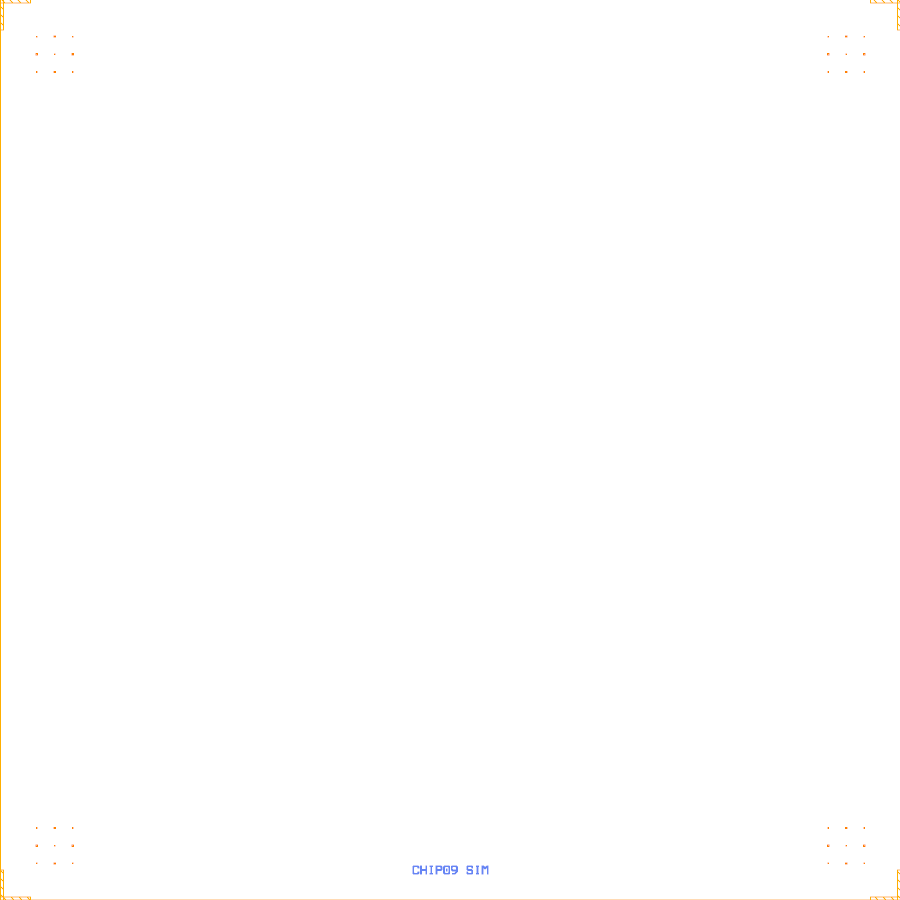

WindowsPath('build/legacy_steps/chip_09_resonators_expt_sim_1_frame.png')

In [4]:
d = Designer(ID, box=(0, 0, L.W, L.H), chip={"name_chip": "CHIP09 SIM", "cheese": "original"}, live=LIVE)
print(d.design.chip.box, d.design.pdk)
L.step_snapshot(d, "1_frame")

## 4 · Pads (PDK pad rule) and the serpentine feedline

The two "Connector Pad 2" bond pads (`BondPad`: 400 × 450 µm pad, 450 µm taper, 225 µm ground gap) go at the
legacy feedline ends (∓2625, 0) with the legacy rotations; `edge="auto"` slides each one perpendicular to its
nearest die edge until the outer edge of its etch is **`pad_edge` = 100 µm** (the design-area margin,
`get_pdk().frame.pad_edge`) from the die edge — the PDK pad rule, which wins over the original.

The feedline is a qcc **route** from pad to pad (`d.route`), through the legacy path's corners, with the
legacy 150 µm corner radius and the 10/6 µm CPW: a route is a real connection, so pads and feedline are one
conductor in the netlist, and its first and last straights simply follow the pads.

**Corner radius.** A route leaves each port straight for one corner radius and needs one more radius of straight before its first turn. With the pads 100 µm in, the first legacy corner is only 275 µm from the pad port, less than 2 × 150 µm, so the feedline takes the largest radius that fits, in 5 µm steps: **135 µm** (`R_FEED`, computed below from the pad position). Every corner keeps its legacy position, so the resonators and the hole columns keep their place beside the runs.

pad etch → die edge (µm): {'PL': 100.0, 'PR': 100.0} | rule: 100.0
pad port → first corner 275 µm → corner radius 135 µm (legacy 150 µm)


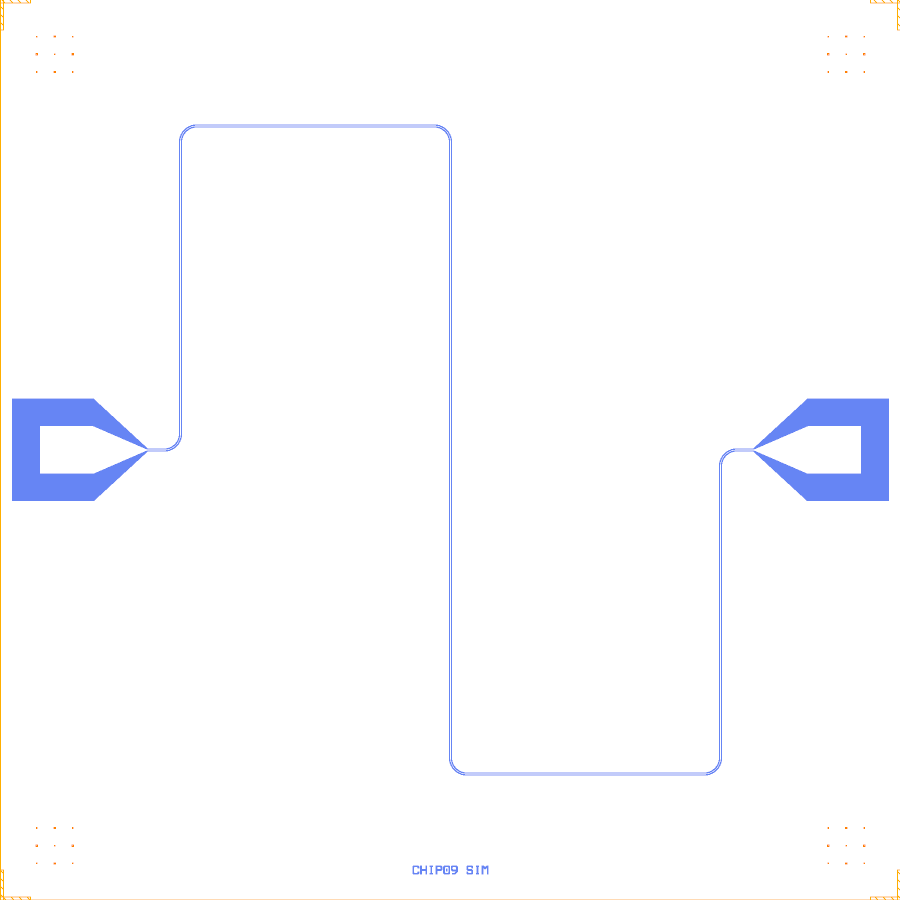

feedline 15502.3 µm (legacy rounded path 15663.7 µm)


In [5]:
PAD = dict(pad_width=400, pad_gap=225, pad_height=450, taper_length=450, a=10, b=6, rounded=False)  # "Connector Pad 2"
with d.batch():
    pl = d.add("PL", "BondPad", **L.place(-LB.C07_PAD_X, 0, 3), edge="auto", **PAD)   # legacy (−2625, 0), rot 3
    pr = d.add("PR", "BondPad", **L.place(LB.C07_PAD_X, 0, 1), edge="auto", **PAD)    # legacy (+2625, 0), rot 1
# a route leaves a port straight for one corner radius and needs one more radius before its first turn
FIRST = L.at(*LB.C09_FEED_PTS[1])[0] - C.port_xy(d, "PL.a")[0]      # pad port → first legacy corner (µm)
R_FEED = min(LB.C09_FEED_R, 5 * int(FIRST / 2 / 5))                # largest radius that fits, 5 µm steps
d.route("FL", pl.a, pr.a, a=10, b=6, r=R_FEED, nodes=[L.at(*p) for p in LB.C09_FEED_PTS[1:-1]])
print("pad etch → die edge (µm):", L.edge_gaps(d), "| rule:", get_pdk().frame.pad_edge)
print(f"pad port → first corner {FIRST:g} µm → corner radius {R_FEED:g} µm (legacy {LB.C09_FEED_R:g} µm)")
L.step_snapshot(d, "2_pads_feedline")
print("feedline", round(d.result.route_lengths()["FL"], 1), "µm (legacy rounded path 15663.7 µm)")

## 5 · Components: the six λ/4 resonators

Each `CoupledResonator` is the legacy `Coupled Resonator` PCell (`L.coupled_resonator` maps the legacy
parameters): a meandered 10/6 µm λ/4 (`cpw_len`), shorted at the end of a straight 299.5 µm coupler beside the
feedline behind a `cgap` µm ground strip, with its own open end (`ground=True`). `d.couple("K_Rn", "Rn",
"FL")` declares the coupler ∥ feedline coupling (a coupling may name a route: its conductor); the netlist makes
it a hanger κ element (step 8). `d.targets` stores the source's target frequencies.

| resonator | cpw_len (µm) | cgap (µm) | target (GHz) |
|---|---|---|---|
| R2 | 4410 | 4 | 7 |
| R3 | 5200 | 4 | 6 |
| R6 | 6200 | 4 | 5 |
| R8 | 5590 | 4 | 5.5 |
| R9 | 5340 | 4 | 5.75 |
| R12 | 4250 | 4 | 7.2 |

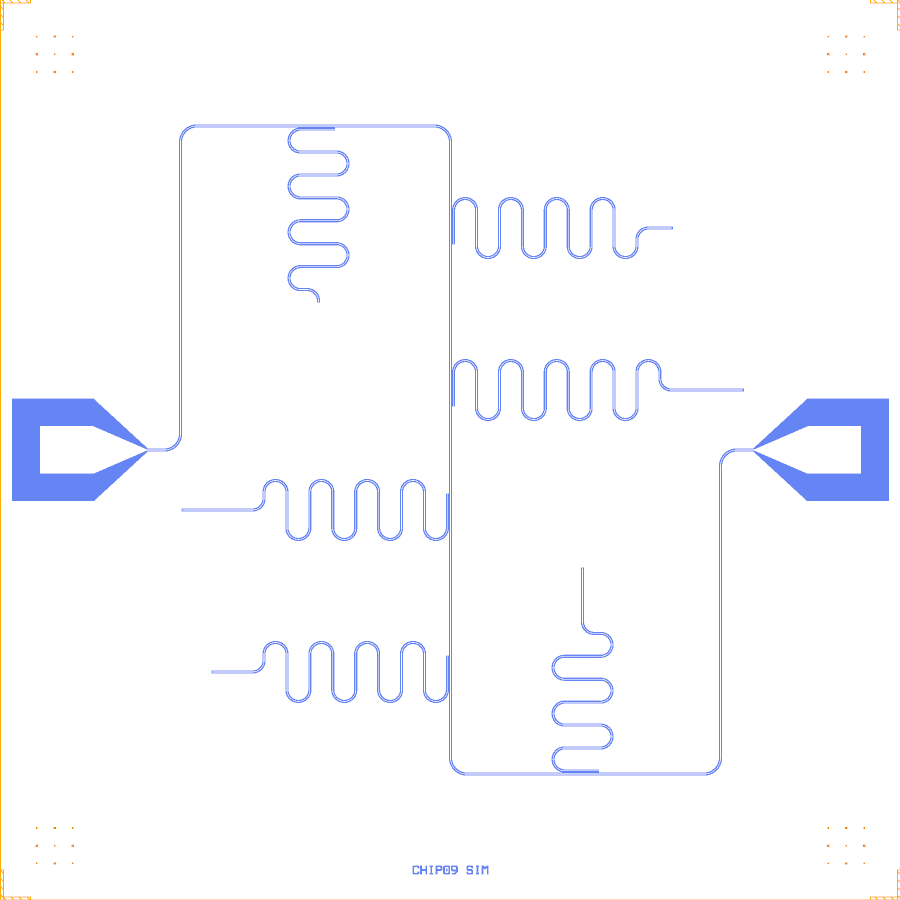

WindowsPath('build/legacy_steps/chip_09_resonators_expt_sim_3_resonators.png')

In [6]:
with d.batch():
    for n, (x, y, rot, mirror, over, f) in LB.C09S_RES.items():
        p = LB.C09_RES_COMMON | over
        d.add(n, "CoupledResonator", **L.place(x, y, rot, mirror), **L.coupled_resonator(**p))
        d.couple(f"K_{n}", n, "FL", note=f"{p['clength']} µm coupler beside the feedline FL")
d.targets(**{n: {"f_GHz": r[5]} for n, r in LB.C09S_RES.items()})
display(Markdown("\n".join(["| resonator | cpw_len (µm) | cgap (µm) | target (GHz) |", "|---|---|---|---|"] + [
    f"| {n} | {(LB.C09_RES_COMMON | r[4])['cpw_len']} | {(LB.C09_RES_COMMON | r[4])['cgap']} | {r[5]:g} |"
    for n, r in LB.C09S_RES.items()])))
L.step_snapshot(d, "3_resonators")

## 6 · The source's cheese, and centring

**Cheese — the original wins.** The source etches its own flux-trapping holes: eight arrays of 5 µm squares on a
15 × 20 µm pitch (`FluxHoleArray`, drawn on 1/0) along the feedline runs. The original has cheese, so the chip
keeps `cheese="original"` (step 3) and the build adds no PDK band.

**Centring (PDK placement rule).** `L.center_circuit` measures the circuit (instances and routes; free text
labels are excluded from the measure but move with everything) and shifts the design to the middle of the
die when it is more than 50 µm off. Then the design is saved: the JSON is what every later step reads.

centring shift (µm): (0.0, 0.0) | <Designer chip_09_resonators_expt_sim: 16 instances, 1 routes, live=False> → examples\designs\legacy\chip_09_resonators_expt_sim.json


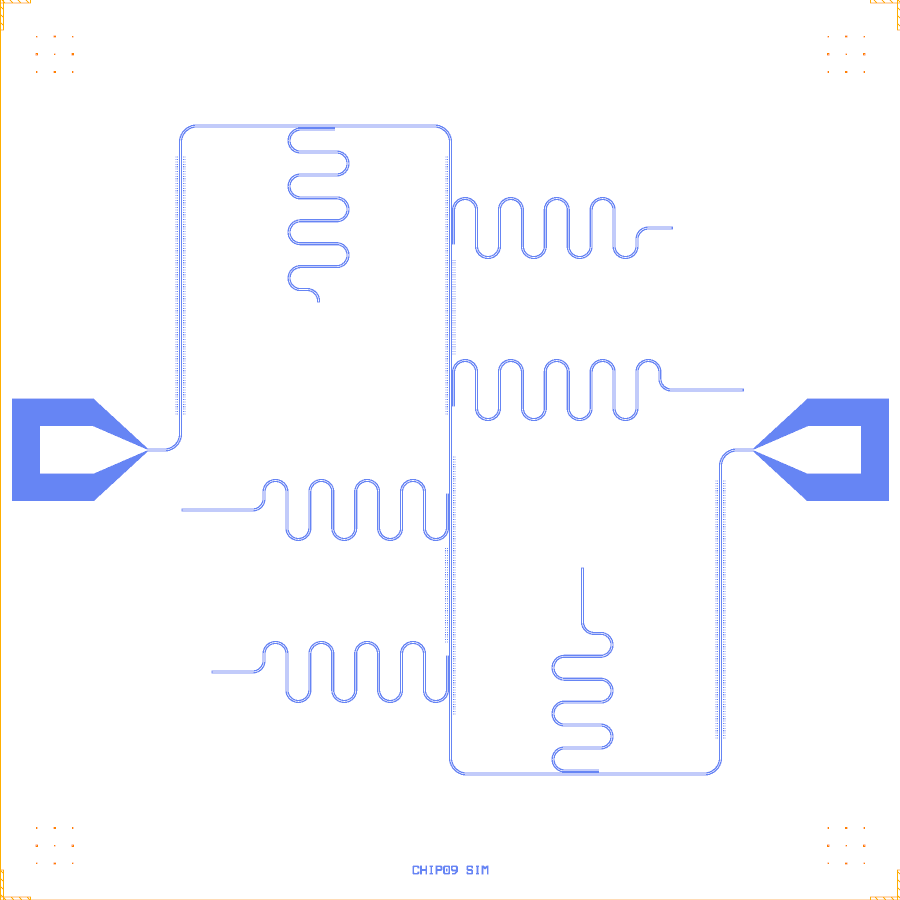

WindowsPath('build/legacy_steps/chip_09_resonators_expt_sim_4_holes.png')

In [7]:
with d.batch():
    for k, (x, y, nx, ny) in enumerate(LB.C09S_HOLES):
        d.add(f"FH{k}", "FluxHoleArray", at=L.at(x, y), hole_size=5, pitch_x=15, pitch_y=20, nx=nx, ny=ny)
for n in LB.C09S_RES:                      # FEM groups: each resonator (the export adds the nearby feedline)
    d.sim_group(n, [n], margin_um=300, analyses=["q3d_cmatrix", "eigenmode_epr"])
SHIFT = L.center_circuit(d)
DESIGN = d.save(OUT / f"{ID}.json")
print("centring shift (µm):", SHIFT, "|", d, "→", DESIGN)
L.step_snapshot(d, "4_holes")

## 7 · DRC

`d.drc()` builds the chip and checks it: **errors** (overlapping etch of unrelated cells, ports not landing,
parts outside the chip) must be fixed; **warnings** are reported for a person to judge (a dangling open end,
two cells' bounding boxes touching); **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`) flag
values outside the PDK margins — they are never retuned for, only listed. `C.pdk_report(d)` summarises the
PDK checks: cheese source, content centring, junction types and the design warnings.

Expected: zero errors; `dangling_port` on the six resonator `end`s (the open ends: nothing connects there by
design) and `overlap` of a hole-array bounding box with a resonator (`FH3` / `R9`: no hole comes within 1 µm of
R9's etch; the XOR in step 14 confirms the legacy placement). No PDK design warnings. `pdk_report`: cheese
"the original design's own", content centre (0, 0).

In [8]:
drc = d.drc()
print(drc)
display(Markdown(C.pdk_report(d)))

warning dangling_port R12.end is not connected (no route or snap)
warning dangling_port R2.end is not connected (no route or snap)
warning dangling_port R3.end is not connected (no route or snap)
warning dangling_port R6.end is not connected (no route or snap)
warning dangling_port R8.end is not connected (no route or snap)
warning dangling_port R9.end is not connected (no route or snap)
warning overlap       FH3 and R9 overlap


| check | value |
|---|---|
| cheese | the original design's own (or none) |
| content centre − die centre | (+0, +0) µm |
| junction types | — |
| PDK design warnings | 0 (none) |

## 8 · Netlist and LOM

`d.lom()` turns the layout into a lumped-element circuit. The feedline route and both pads are one node (`FL`)
with a 50 Ω port at each pad (the bond pads' LOM model); each resonator is a λ/4 `TLres` (drawn length, ε_eff of
the 10/6 µm CPW on sapphire, shorted at the coupler start) from its node to ground, plus a `HANGER` κ element to
the feedline (`K_Rn`, from the coupler length and gap). The six unconnected ports are the resonators' open
ends.

In [9]:
lb = d.lom()
C.show_netlist(lb)
print(C.lom_summary(lb))

**8 nodes · 14 branches · 0 controls · 6 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `FL` | `FL`, `PL.pad`, `PR.pad` |
| `R2.res` | `R2.res` |
| `R3.res` | `R3.res` |
| `R6.res` | `R6.res` |
| `R8.res` | `R8.res` |
| `R9.res` | `R9.res` |
| `R12.res` | `R12.res` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_PL` | R | `FL` – `gnd` | 50 Ω |
| `Port_PR` | R | `FL` – `gnd` | 50 Ω |
| `R2` | TLres | `R2.res` – `gnd` | lambda/4, 4410 µm, 7.145 GHz |
| `K_R2` | HANGER | `R2.res` – `FL` | κ 0.338 MHz (L 300 µm) |
| `R3` | TLres | `R3.res` – `gnd` | lambda/4, 5200 µm, 6.059 GHz |
| `K_R3` | HANGER | `R3.res` – `FL` | κ 0.206 MHz (L 300 µm) |
| `R6` | TLres | `R6.res` – `gnd` | lambda/4, 6200 µm, 5.082 GHz |
| `K_R6` | HANGER | `R6.res` – `FL` | κ 0.122 MHz (L 300 µm) |
| `R8` | TLres | `R8.res` – `gnd` | lambda/4, 5590 µm, 5.637 GHz |
| `K_R8` | HANGER | `R8.res` – `FL` | κ 0.166 MHz (L 300 µm) |
| `R9` | TLres | `R9.res` – `gnd` | lambda/4, 5340 µm, 5.901 GHz |
| `K_R9` | HANGER | `R9.res` – `FL` | κ 0.191 MHz (L 300 µm) |
| `R12` | TLres | `R12.res` – `gnd` | lambda/4, 4250 µm, 7.414 GHz |
| `K_R12` | HANGER | `R12.res` – `FL` | κ 0.378 MHz (L 300 µm) |

**Unconnected ports:** `R12.end`, `R2.end`, `R3.end`, `R6.end`, `R8.end`, `R9.end`

{'nodes': 7, 'branches': 14, 'controls': 0, 'unconnected': 6}


## 9 · LOM simulation

Each resonator with the feedline and its two 50 Ω pads (QuCat normal mode and κ, QuTiP-dressed f_r), against the
targets, then compared with design 14's simulated calibration table where it has the same length
(`_legacy_b.D14_SIM_TABLE`).

In [10]:
results = C.simulate_groups(d, {n: [n, "FL", "PL", "PR"] for n in LB.C09S_RES})
display(Markdown(C.groups_md(results, d.data["targets"])))
sim14 = {L_um: f for _, L_um, f in LB.D14_SIM_TABLE}
rows = ["| resonator | cpw_len (µm) | clength / cgap (µm) | target (GHz) | design-14 simulation (GHz) | LOM bare λ/4 (GHz) "
        "| LOM loaded (GHz) | κ (MHz) |", "|---|---|---|---|---|---|---|---|"]
for n, (x, y, rot, mirror, over, f) in LB.C09S_RES.items():
    p = LB.C09_RES_COMMON | over
    sim = sim14.get(p["cpw_len"])
    rows.append(f"| {n} | {p['cpw_len']} | {p['clength']} / {p['cgap']} | {f:g} | {'–' if sim is None else f'{sim:.3f}'} | "
                f"{lb.model.branches[n].value['f_GHz']:.3f} | {results[n].params[f'{n}.f_GHz']:.3f} | "
                f"{results[n].params[f'{n}.kappa_MHz']:.3g} |")
display(Markdown("\n".join(rows)))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| R2 | – | – | – | R2 | 7.104 (7) | 0.33 | – |
| R3 | – | – | – | R3 | 6.03 (6) | 0.203 | – |
| R6 | – | – | – | R6 | 5.0613 (5) | 0.12 | – |
| R8 | – | – | – | R8 | 5.6111 (5.5) | 0.163 | – |
| R9 | – | – | – | R9 | 5.8726 (5.75) | 0.187 | – |
| R12 | – | – | – | R12 | 7.3699 (7.2) | 0.369 | – |

| resonator | cpw_len (µm) | clength / cgap (µm) | target (GHz) | design-14 simulation (GHz) | LOM bare λ/4 (GHz) | LOM loaded (GHz) | κ (MHz) |
|---|---|---|---|---|---|---|---|
| R2 | 4410 | 299.5 / 4 | 7 | – | 7.145 | 7.104 | 0.33 |
| R3 | 5200 | 299.5 / 4 | 6 | 6.188 | 6.059 | 6.030 | 0.203 |
| R6 | 6200 | 299.5 / 4 | 5 | – | 5.082 | 5.061 | 0.12 |
| R8 | 5590 | 299.5 / 4 | 5.5 | 5.787 | 5.637 | 5.611 | 0.163 |
| R9 | 5340 | 299.5 / 4 | 5.75 | – | 5.901 | 5.873 | 0.187 |
| R12 | 4250 | 299.5 / 4 | 7.2 | 7.365 | 7.414 | 7.370 | 0.369 |

**Reading the numbers** (LOM of this run). The _sim plan's R6 (6200 µm) and R8 (5590 µm) are the lengths
chip_05 uses for 5.0 and 5.5 GHz. As on chip_09 and chip_07, the LOM's bare λ/4 sits 0.06–0.21 GHz above the
written targets: the legacy lengths come from bare-resonator simulations (no claws) with a slightly
longer effective length than the drawn one. Design 14's simulated values for 5590 and 5200 µm are ≈ 2–3 %
above the LOM, for 4250 µm (R12, 7.365 GHz) 0.7 % below it.

## 10 · FEM: send the job

Each sim group is cut out of the chip (its instances plus a margin of ground), with the PDK stack (sapphire
650 µm, ε_r 10.25) and **without cheese** (simulation exports never have it), and written as a job folder
under `build/jobs/` (`C.export_sims` → `build_simulation` + `export_job`): a Q3D C-matrix job by default,
`analysis="eigenmode_epr"` for the eigenmode / EPR job. With `RUN_FEM = True` and AEDT 2024 R1 (v241) or
newer on this machine, `L.fem_send` solves each job in a **new batch, non-graphical** AEDT
(`sim_tools.hfss.solve_job`) — it never touches an AEDT window you have open. The default here is
`False`: export only.

Here: one Q3D C-matrix job per resonator, cut out with a 300 µm margin that takes in the neighbouring stretch of
the routed feedline. The C-matrix job puts an edge port on the feedline (net `FL`); the eigenmode job
(`analysis="eigenmode_epr"`) terminates both feedline ends leaving the box with 50 Ω lumped ports, so κ comes
from the eigenmode Q. Each λ/4 resonator is shorted at its coupler end, so its centre conductor is ground for
the C-matrix.

In [11]:
RUN_FEM = False                       # True: solve the exported jobs here (AEDT 2024 R1+, batch)
jobs = C.export_sims(DESIGN)
display(Markdown(C.jobs_md(jobs)))
display(Markdown(L.fem_send(jobs, run=RUN_FEM)))

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| R2 | `build/jobs/chip_09_resonators_expt_sim_R2_q3d_cmatrix` | 1 · edge · `FL` | `FL` |
| R3 | `build/jobs/chip_09_resonators_expt_sim_R3_q3d_cmatrix` | 1 · edge · `FL` | `FL` |
| R6 | `build/jobs/chip_09_resonators_expt_sim_R6_q3d_cmatrix` | 1 · edge · `FL` | `FL` |
| R8 | `build/jobs/chip_09_resonators_expt_sim_R8_q3d_cmatrix` | 1 · edge · `FL` | `FL` |
| R9 | `build/jobs/chip_09_resonators_expt_sim_R9_q3d_cmatrix` | 1 · edge · `FL` | `FL` |
| R12 | `build/jobs/chip_09_resonators_expt_sim_R12_q3d_cmatrix` | 1 · edge · `FL` | `FL` |

AEDT on this machine: `C:\Program Files\AnsysEM\v241\Win64\ansysedt.exe` (v241)

`RUN_FEM = False`: 6 job(s) exported, none solved. Set `RUN_FEM = True` to solve them here (batch, non-graphical), or run `qcc sim run <job>` on a machine with AEDT 2024 R1+.

## 11 · Bring the results back

A solved job leaves `results/results.json` in its folder. `fill(model, DESIGN, job)` then replaces the LOM's
component estimates by the FEM C-matrix, matched by net name (the net names are the ones in the job table
above), and the LOM is simulated again with them. `L.fem_bring_back` does this for every job that has
results and says which have none yet.

No job has been solved yet, so the cell says so; with eigenmode results the loaded f_r and Q of each resonator
would appear next to the LOM's.

In [12]:
display(Markdown(L.fem_bring_back(d, DESIGN, jobs, groups=None)))

No FEM results yet for 6 job(s) (`build/jobs/chip_09_resonators_expt_sim_R2_q3d_cmatrix`, `build/jobs/chip_09_resonators_expt_sim_R3_q3d_cmatrix`, `build/jobs/chip_09_resonators_expt_sim_R6_q3d_cmatrix`, `build/jobs/chip_09_resonators_expt_sim_R8_q3d_cmatrix`, …). After a solve each job holds `results/results.json`; this cell then fills the LOM with the extracted C-matrix (`fill(model, DESIGN, job)`) and shows the estimate next to the FEM value per capacitance, and f_q / α / f_r / χ re-simulated with them.

## 12 · Iterate: change one property and re-simulate

A variant is a copy of the saved design with one parameter changed. Here R12 is lengthened by 150 µm
(`cpw_len`): a λ/4 scales as 1/L, so f_r drops by about 3 %, towards its written target; κ barely moves (same
coupler). The copy is not saved — the chip keeps the legacy length (values are flagged, never retuned).

In [13]:
d2 = Designer.load(DESIGN, live=False, verbose=False)      # a copy of the saved design
L_R12 = (LB.C09_RES_COMMON | LB.C09S_RES["R12"][4])["cpw_len"]
d2["R12"].set(cpw_len=L_R12 + 150)
after = C.simulate_groups(d2, {"R12": ["R12", "FL", "PL", "PR"]})["R12"]
display(Markdown(L.compare_md(results["R12"], after, keys=["R12.f_GHz", "R12.kappa_MHz"],
                              label=(f"cpw_len {L_R12} µm", f"cpw_len {L_R12 + 150} µm"))))

| parameter | cpw_len 4250 µm | cpw_len 4400 µm | Δ |
|---|---|---|---|
| `R12.f_GHz` | 7.3699 | 7.1201 | -0.2498 |
| `R12.kappa_MHz` | 0.36882 | 0.33273 | -0.03609 |

## 13 · Build and export

The design is saved as JSON (`DESIGN`, step 6): it is the source of truth — the layout, the netlist, the
FEM jobs and the mask are all made from it. The **fab mask** (`export_fab`) keeps only the PDK fab layers
(1/0 etch, 2/0 + 4/0 junction fingers, 3/0 second-metal keep-out, 50–53/0 spacer, 100/0 boundary, 1000/0 +
1001/0 markers), rounds the corners (radius ∝ each polygon's shortest dimension) and keeps the build's
cheese. **Simulation exports** never carry cheese; they drop airbridges unless asked
(`build_simulation(..., airbridges=True)`); the legacy chips have none.

Here: `cheese=False` at export, because this chip's cheese is the source's own flux holes, drawn on 1/0 as part
of the design; they stay in the mask and no PDK band is added.

The same from a shell:

```
qcc build examples/designs/legacy/chip_09_resonators_expt_sim.json                    # layout → build/chip_09_resonators_expt_sim.oas
qcc mask  examples/designs/legacy/chip_09_resonators_expt_sim.json --no-cheese          # fab mask with the PDK rules
qcc sim build examples/designs/legacy/chip_09_resonators_expt_sim.json -g R2 -a q3d_cmatrix   # one FEM job (step 10)
qcc sim run build/jobs/chip_09_resonators_expt_sim_R2_q3d_cmatrix              # solve it (AEDT 2024 R1+)
```

In [14]:
display(Markdown(L.fab_md(d, cheese=False)))

Fab mask: `build/chip_09_resonators_expt_sim_fab.oas` · cheese source **none** (0 PDK-band holes) · corner rounding on

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 1473 |
| 3/0 | M3 | 7 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

## 14 · Snapshots and comparison with the legacy geometry

The full chip; zooms on the central run with R3 (coupler beside the vertical feedline, flux holes) and on R2
(no qubits or junctions on this chip); then the legacy chip drawn by the author's own PCells and path (read-only
harness, moved by the centring shift) and the per-instance XOR on 1/0.

Expected XOR: 0 on the resonators, holes; the pads (moved 100 µm in by the pad
rule) and the feedline (shorter end runs, 135 µm instead of 150 µm corners) differ by design.

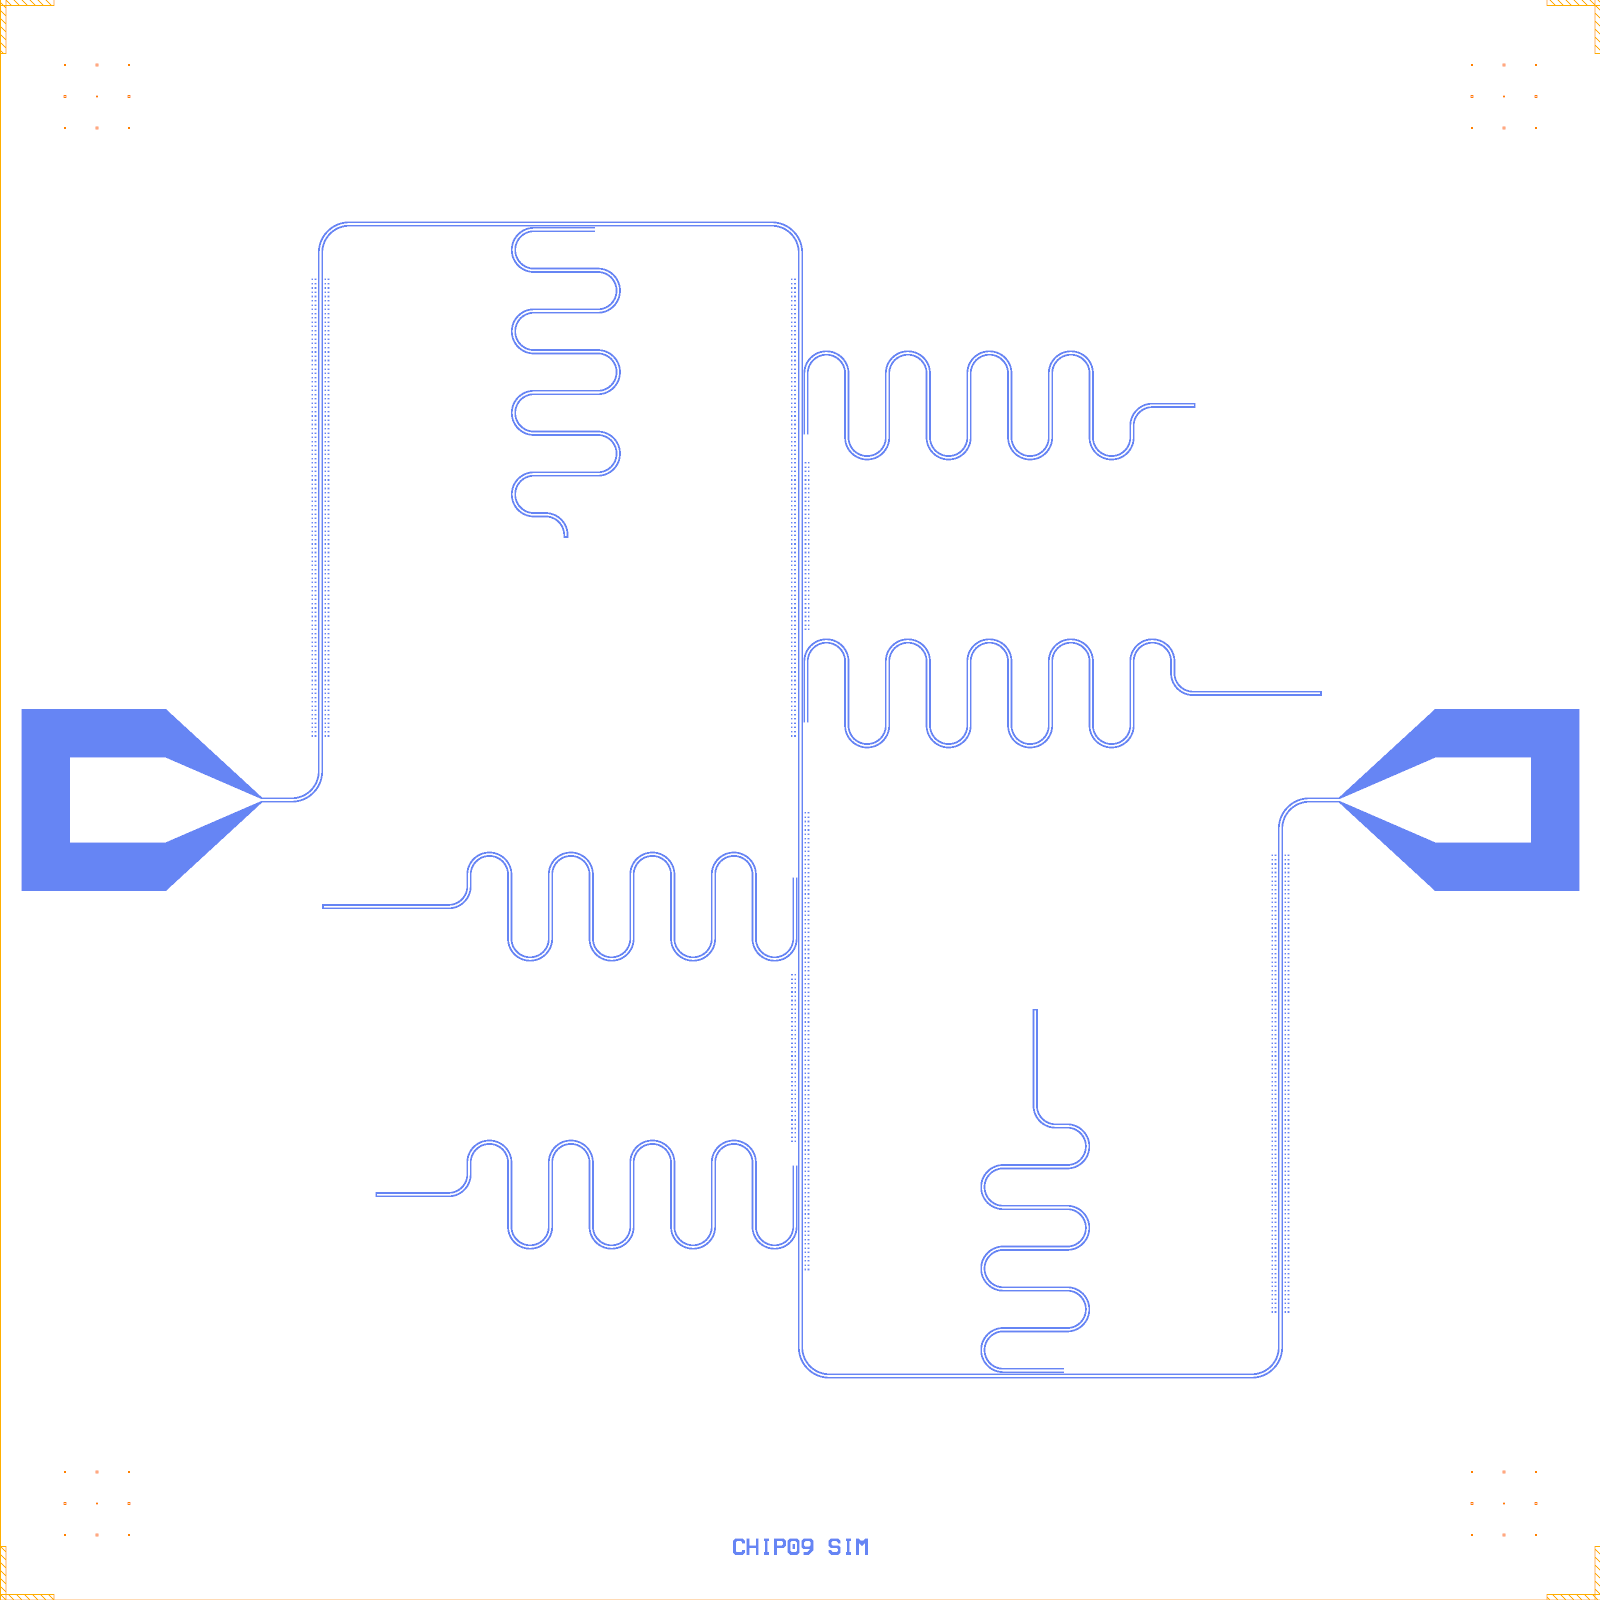

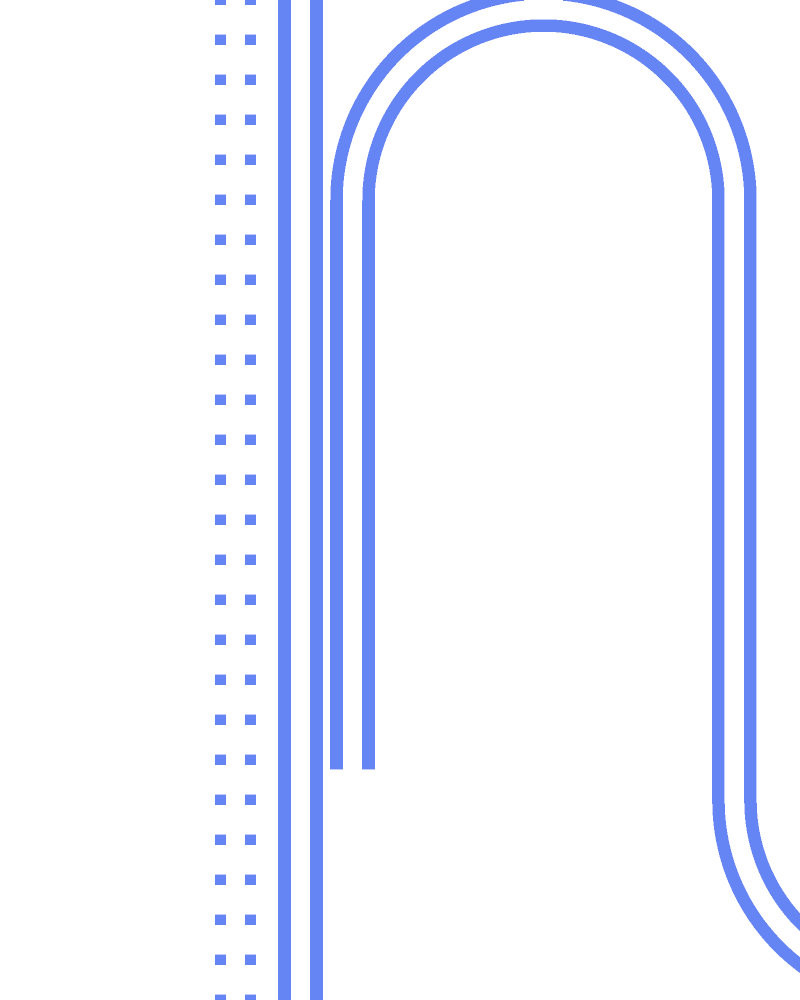

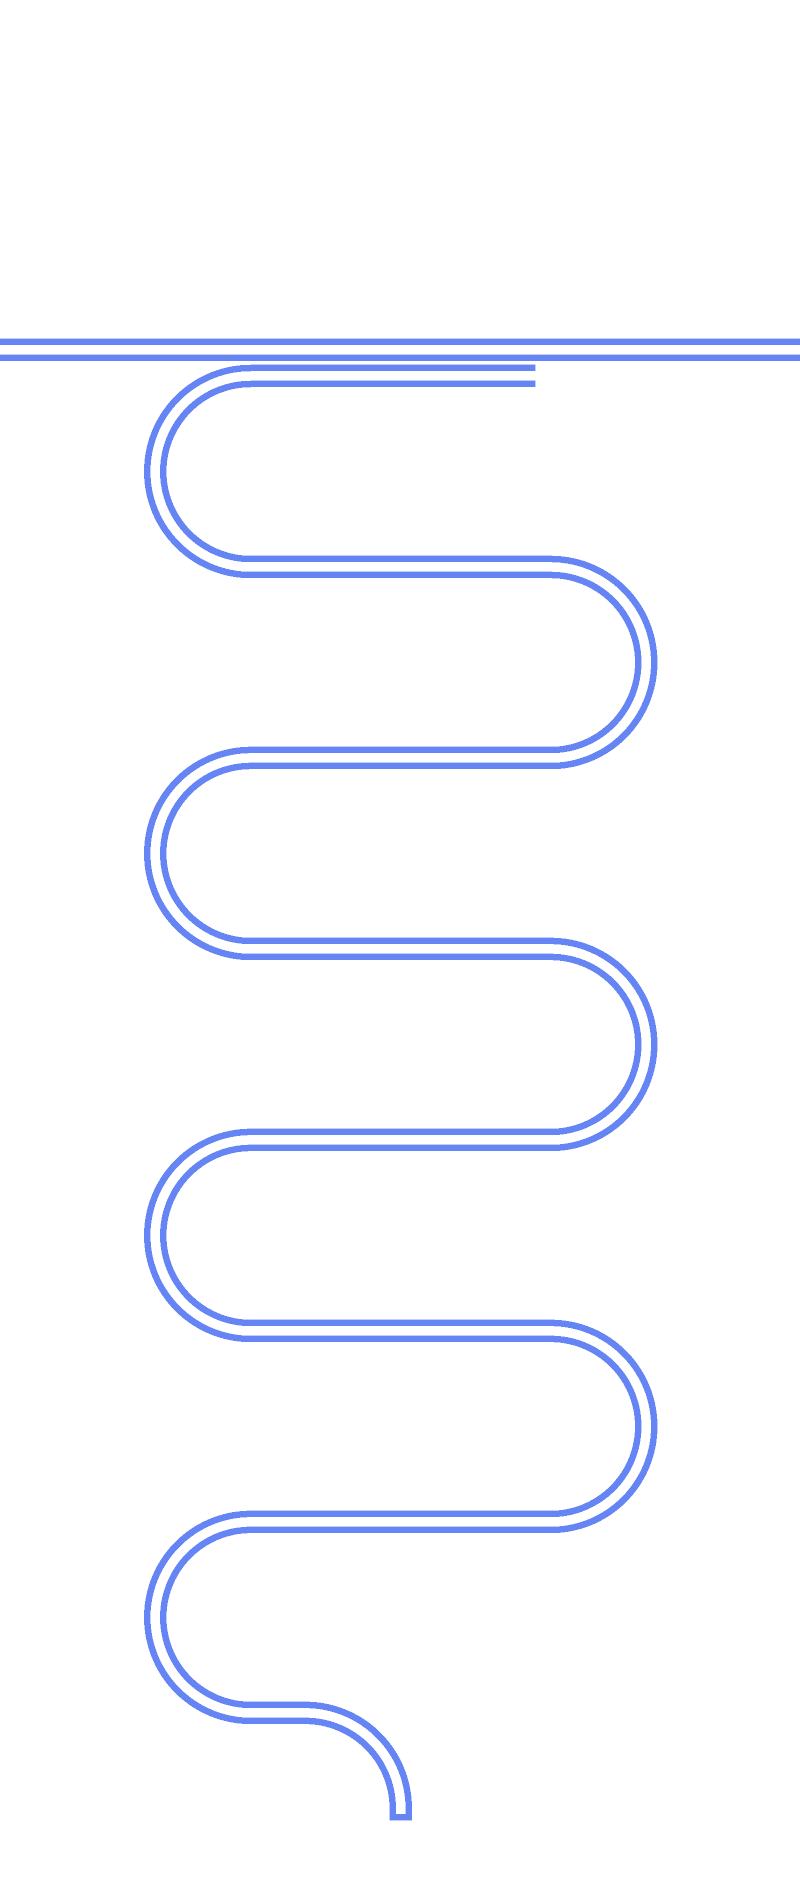

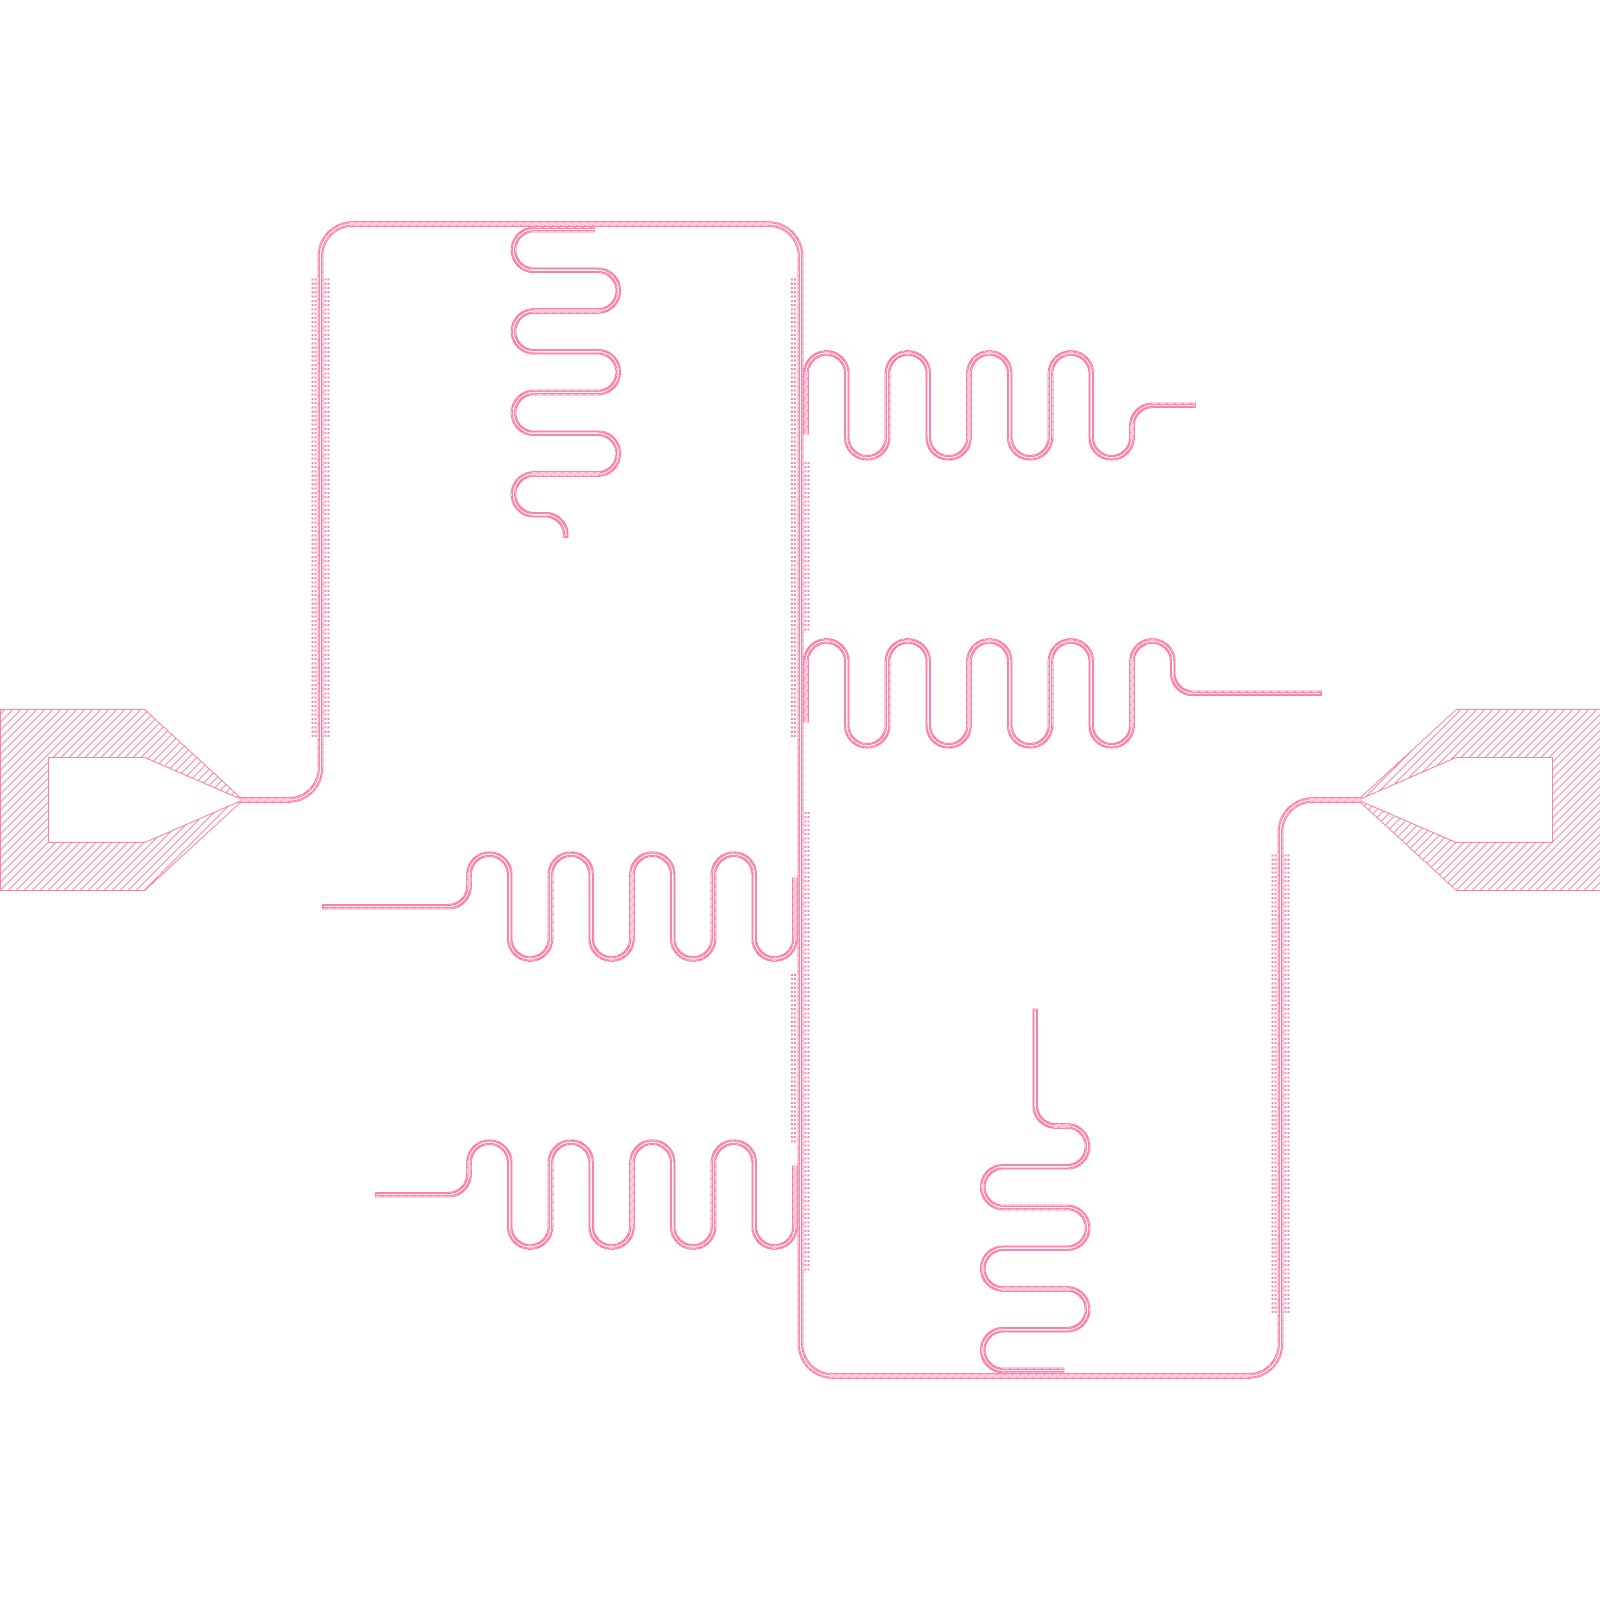

**XOR against the legacy `_sim` chip** (fab negative)

| instance | legacy etch (µm²) | rebuilt etch (µm²) | XOR (µm²) | XOR / legacy |
|---|---|---|---|---|
| FL | 595953 | 606139 | 35883.4 | 6.02% |
| PL | 497700 | 491633 | 227540.5 | 45.72% |
| PR | 497700 | 491633 | 227540.5 | 45.72% |
| R2 | 52871 | 52871 | 0.0 | 0.00% |
| R3 | 62351 | 62351 | 0.0 | 0.00% |
| R6 | 74351 | 74351 | 0.0 | 0.00% |
| R8 | 67031 | 67031 | 0.0 | 0.00% |
| R9 | 64081 | 64081 | 0.0 | 0.00% |
| R12 | 50952 | 50952 | 0.0 | 0.00% |
| FH0 | 5400 | 5400 | 0.0 | 0.00% |
| FH1 | 5400 | 5400 | 0.0 | 0.00% |
| FH2 | 5400 | 5400 | 0.0 | 0.00% |
| FH3 | 2000 | 2000 | 0.0 | 0.00% |
| FH4 | 2000 | 2000 | 0.0 | 0.00% |
| FH5 | 5400 | 5400 | 0.0 | 0.00% |
| FH6 | 5400 | 5400 | 0.0 | 0.00% |
| FH7 | 5400 | 5400 | 0.0 | 0.00% |

max XOR without pads and feedline: 0.0 µm²


In [15]:
C.show_snapshot(d, OUT / f"{ID}.png", box=(0, 0, 7500, 7500), size=(1600, 1600))
C.show_snapshot(d, OUT / f"{ID}_coupler.png", box=(3600, 5350, 4000, 5850), size=(800, 1000), width=320)  # R3 coupler
C.show_snapshot(d, OUT / f"{ID}_resonator.png", box=(2250, 4900, 3050, 6800), size=(800, 1900), width=320)  # R2
if L.legacy_available():
    from quantcore_circuits.live.snapshot import snapshot
    ref = L.shift_reference(LB.chip09_sim_reference(), *SHIFT)
    snapshot(ref.write("build/legacy_b/chip_09_resonators_expt_sim_legacy.oas"), OUT / f"{ID}_legacy.png",
             box=(0, 0, 7500, 7500), size=(1600, 1600))
    display(Image(filename=str(OUT / f"{ID}_legacy.png"), width=640))
    table, xor = L.xor_table(d, ref)
    display(Markdown("**XOR against the legacy `_sim` chip** (fab negative)\n\n" + table))
    print("max XOR without pads and feedline:", round(max(v for k, v in xor.items() if k not in ("PL", "PR", "FL")), 1), "µm²")
else:
    print("components/ (legacy library) not present: no legacy reference")

## 15 · Summary

- **Matches the source:** the six resonators and the flux-hole columns (XOR 0); the
  feedline through the legacy corners (shorter end runs and a 135 µm corner radius, the largest that fits the pad rule).
- **Differs, by the PDK:** pads `pad_edge` = 100 µm from the die edge (feedline 15502 µm, 161 µm shorter; corners r = 135 µm), the PDK frame and device ID
  `CHIP09 SIM`.
- **Cheese:** the original's flux holes, no PDK band. **Centring:** already centred.
- **Open:** the LOM sits above the written targets (bare λ/4 lengths from simulations with a longer effective
  length); no PDK design warnings.